# Scoring and report

Hit rates, peak ratios, POD/FAR/CSI, conditional skill, bootstrap, report figures and report.md.

Cells are the original session code in execution order (exported verbatim; only secrets handling and artifact paths were changed). Each cell starts with a comment giving its original index, conda environment and run status. Exploratory and failed cells are kept, so later cells that rely on their partial state still make sense.


In [ ]:
# Setup: run from the repository root; helper modules live in prod/
import os, sys
if os.path.basename(os.getcwd())=='notebooks': os.chdir('..')
sys.path.insert(0, 'prod')
os.makedirs('out', exist_ok=True)
from style import apply_figure_style  # stand-in for the figure style used in the session


In [125]:
# [orig cell 124 | env: precip | status: ok]
PEc=PEa[[ (t,k) in common for t,k in zip(PEa.threshold,PEa.key)]].copy()
PEc['hit']=PEc.prod_0h>=PEc.threshold; PEc['hit_pm1']=PEc.prod_pm1h>=PEc.threshold
PEc['hit10']=PEc.prod_0h>=10; PEc['hit1']=PEc.prod_0h>=1; PEc['ratio']=PEc.prod_0h/PEc.peak_mm_h
rng=np.random.default_rng(1)
def boot_ci(df,col,B=500):
    st=df.s.values; x=df[col].values.astype(float); us=np.unique(st); gi={u:np.where(st==u)[0] for u in us}
    b=[x[np.concatenate([gi[u] for u in rng.choice(us,len(us))])].mean() for _ in range(B)]; return np.quantile(b,[.025,.975])
rows=[]
for (p,T,N),d in PEc.groupby(['product','threshold','nbhd']):
    lo,hi=boot_ci(d,'hit')
    rows.append(dict(product=p,label=PRODS[p],type=PTYPE[p],threshold=T,nbhd=N,n_events=len(d),hit_strict=d.hit.mean(),hit_strict_lo=lo,hit_strict_hi=hi,
                     hit_strict_pm1h=d.hit_pm1.mean(),hit_ge10=d.hit10.mean(),hit_ge1=d.hit1.mean(),
                     ratio_median=d.ratio.median(),ratio_q25=d.ratio.quantile(.25),ratio_q75=d.ratio.quantile(.75)))
DS=pd.DataFrame(rows).merge(SCa[['product','threshold','nbhd','POD_h','FAR_h','CSI_h','FBI_h','n_hours']],on=['product','threshold','nbhd'])
order=list(PRODS); DS['o']=DS['product'].map({p:i for i,p in enumerate(order)}); DS=DS.sort_values(['threshold','o','nbhd']).drop(columns='o')
DS.to_csv('out/detection_scores.csv',index=False)
print(DS[DS.nbhd=='N1'].pivot_table(index='label',columns='threshold',values='hit_strict',sort=False).round(3))
print(DS[DS.nbhd=='N16'].pivot_table(index='label',columns='threshold',values='hit_strict',sort=False).round(3))
print(DS[DS.threshold==30].pivot_table(index='label',columns='nbhd',values='CSI_h',sort=False)[['N1','N4','N9','N16']].round(3))

threshold                       20     30     40     50
label                                                  
MRMS gauge-corrected (1 km)  0.529  0.426  0.347  0.327
MRMS radar-only (1 km)       0.462  0.360  0.254  0.188
Stage IV (4 km)              0.444  0.350  0.283  0.244
NLDAS-2 (0.125°)             0.172  0.087  0.051  0.027
PERSIANN-CCS (0.04°)         0.050  0.026  0.016  0.004
CMORPH CDR (8 km)            0.033  0.009  0.002  0.000
IMERG V07 Final (0.1°)       0.019  0.005  0.002  0.000
MERRA-2 (0.5°×0.625°)        0.001  0.000  0.000  0.000
threshold                       20     30     40     50
label                                                  
MRMS gauge-corrected (1 km)  0.691  0.582  0.503  0.439
MRMS radar-only (1 km)       0.699  0.584  0.476  0.363
Stage IV (4 km)              0.770  0.697  0.637  0.605
NLDAS-2 (0.125°)             0.332  0.199  0.129  0.067
PERSIANN-CCS (0.04°)         0.152  0.081  0.032  0.018
CMORPH CDR (8 km)            0.108  0.041  0.018

> Original cell 125 ended with status **error** in the session; it is kept for the record.

In [126]:
# [orig cell 125 | env: precip | status: error]
nd=[]
for p in PRODS:
    w=NBall[p][1]['widx']; dx=np.median([x['dx_km'] for x in w if x['ok']]); dy=np.median([x['dy_km'] for x in w if x['ok']])
    for N,k in [('N1',1),('N4',2),('N9',3),('N16',4)]:
        nd.append(dict(product=p,label=PRODS[p],type=PTYPE[p],pixel_dx_km=round(dx,2),pixel_dy_km=round(dy,2),nbhd=N,block=f'{k}x{k}',side_km=round(k*np.sqrt(dx*dy),1),area_km2=round(k*k*dx*dy,1),
                       stations_covered=sum(x['ok'] for x in w)))
ND=pd.DataFrame(nd); ND.to_csv('out/neighborhood_definitions.csv',index=False)
print(ND[ND.nbhd.isin(['N1','N16'])][['label','pixel_dx_km','pixel_dy_km','nbhd','area_km2','stations_covered']].to_string(index=False))
# illustration at Miami
import matplotlib.patches as mpa
sid='USW00012839'; s=sidx[sid]; srow=Vst.iloc[s]
show=['mrms_radaronly','stage4','pccs','cmorph','imerg','nldas2','merra2']
fig,axs=plt.subplots(1,len(show),figsize=(14,2.6))
ncol={'N1':'#08306b','N4':'#2171b5','N9':'#6baed6','N16':'#c6dbef'}
for ax,p in zip(axs,show):
    w=NBall[p][1]['widx'][s]; la_=np.array(w['win_lat']); lo_=np.array(w['win_lon']); m=common.neighborhood_masks(w)
    X=(lo_-srow.lon)*111.32*np.cos(np.radians(srow.lat)); Y=(la_-srow.lat)*110.57
    dxk,dyk=w['dx_km'],w['dy_km']
    for N in ['N16','N9','N4','N1']:
        for (a,b) in zip(*np.where(m[N])):
            ax.add_patch(mpa.Rectangle((X[a,b]-dxk/2,Y[a,b]-dyk/2),dxk,dyk,facecolor=ncol[N],edgecolor='w',lw=0.3,alpha=0.9 if N!='N9' else 0.0,
                                       hatch=None))
    # N9 outline
    r,c=np.where(m['N9']); ax.add_patch(mpa.Rectangle((X[r,c].min()-dxk/2,Y[r,c].min()-dyk/2) if Y[r,c].min()<Y[r,c].max() else (X[r,c].min()-dxk/2,Y[r,c].min()-dyk/2),
                          X[r,c].max()-X[r,c].min()+dxk,Y[r,c].max()-Y[r,c].min()+dyk,fill=False,edgecolor='#e6550d',lw=1.2,ls='--'))
    ax.scatter(X,Y,s=3,c='0.5'); ax.plot(0,0,'*',c='#e6550d',ms=9,mec='k',mew=0.4)
    L=2.6*max(dxk,dyk); ax.set_xlim(-L,L); ax.set_ylim(-L,L); ax.set_aspect('equal')
    ax.set_title(PRODS[p].replace(' (','\n('),fontsize=7,loc='left'); ax.tick_params(labelsize=6)
axs[0].set_ylabel('km from station'); axs[3].set_xlabel('km from station (Miami Intl, ★)')
h=[mpa.Patch(color=ncol[N],label=lab) for N,lab in [('N1','1 pixel'),('N4','2×2'),('N16','4×4')]]+[mpa.Patch(fill=False,edgecolor='#e6550d',ls='--',label='3×3')]
fig.legend(handles=h,loc='upper right',ncol=4,frameon=False,fontsize=7,bbox_to_anchor=(1,1.04))
fig.tight_layout(); fig.savefig('out/neighborhoods_illustration.png',dpi=200,bbox_inches='tight')

                      label  pixel_dx_km  pixel_dy_km nbhd  area_km2  stations_covered
MRMS gauge-corrected (1 km)         0.98         1.11   N1       1.1                79
MRMS gauge-corrected (1 km)         0.98         1.11  N16      17.4                79
     MRMS radar-only (1 km)         0.98         1.11   N1       1.1                79
     MRMS radar-only (1 km)         0.98         1.11  N16      17.4                79
            Stage IV (4 km)         3.76         3.76   N1      14.1                79
            Stage IV (4 km)         3.76         3.76  N16     225.9                79
           NLDAS-2 (0.125°)        12.22        13.90   N1     169.9                75
           NLDAS-2 (0.125°)        12.22        13.90  N16    2718.1                75
       PERSIANN-CCS (0.04°)         3.92         4.45   N1      17.5                79
       PERSIANN-CCS (0.04°)         3.92         4.45  N16     279.2                79
          CMORPH CDR (8 km)         7.14   

Traceback (most recent call last):
  File "<kernel:65>", line 16, in <module>
    w=NBall[p][1]['widx'][s]; la_=np.array(w['win_lat']); lo_=np.array(w['win_lon']); m=common.neighborhood_masks(w)
                                                                                        ^^^^^^^^^^^^^^^^^^^^^^^^^
AttributeError: 'set' object has no attribute 'neighborhood_masks'


In [127]:
# [orig cell 126 | env: precip | status: ok]
import importlib; cm=importlib.import_module('common'); COMMON_EV=common
fig,axs=plt.subplots(1,len(show),figsize=(14,2.7))
for ax,p in zip(axs,show):
    w=NBall[p][1]['widx'][s]; la_=np.array(w['win_lat']); lo_=np.array(w['win_lon']); m=cm.neighborhood_masks(w)
    X=(lo_-srow.lon)*111.32*np.cos(np.radians(srow.lat)); Y=(la_-srow.lat)*110.57; dxk,dyk=w['dx_km'],w['dy_km']
    for N in ['N16','N4','N1']:
        for (a,b) in zip(*np.where(m[N])):
            ax.add_patch(mpa.Rectangle((X[a,b]-dxk/2,Y[a,b]-dyk/2),dxk,dyk,facecolor=ncol[N],edgecolor='w',lw=0.4))
    r,c=np.where(m['N9'])
    ax.add_patch(mpa.Rectangle((X[r,c].min()-dxk/2,Y[r,c].min()-dyk/2),X[r,c].max()-X[r,c].min()+dxk,Y[r,c].max()-Y[r,c].min()+dyk,fill=False,edgecolor='#e6550d',lw=1.2,ls='--'))
    ax.scatter(X,Y,s=2,c='0.55',zorder=3); ax.plot(0,0,'*',c='#e6550d',ms=9,mec='k',mew=0.4,zorder=4)
    L=2.6*max(dxk,dyk); ax.set_xlim(-L,L); ax.set_ylim(-L,L); ax.set_aspect('equal')
    ax.set_title(PRODS[p].replace(' (','\n('),fontsize=7,loc='left'); ax.tick_params(labelsize=6)
axs[0].set_ylabel('km north of station',fontsize=7); axs[3].set_xlabel('km east of station (Miami Intl AP = ★; grey dots = pixel centres)',fontsize=7)
h=[mpa.Patch(color=ncol['N1'],label='station pixel (N1)'),mpa.Patch(color=ncol['N4'],label='2×2 (N4)'),mpa.Patch(fill=False,edgecolor='#e6550d',ls='--',label='3×3 (N9)'),mpa.Patch(color=ncol['N16'],label='4×4 (N16)')]
fig.legend(handles=h,loc='upper right',ncol=4,frameon=False,fontsize=7,bbox_to_anchor=(1,1.06))
fig.tight_layout(); fig.savefig('out/neighborhoods_illustration.png',dpi=200,bbox_inches='tight')

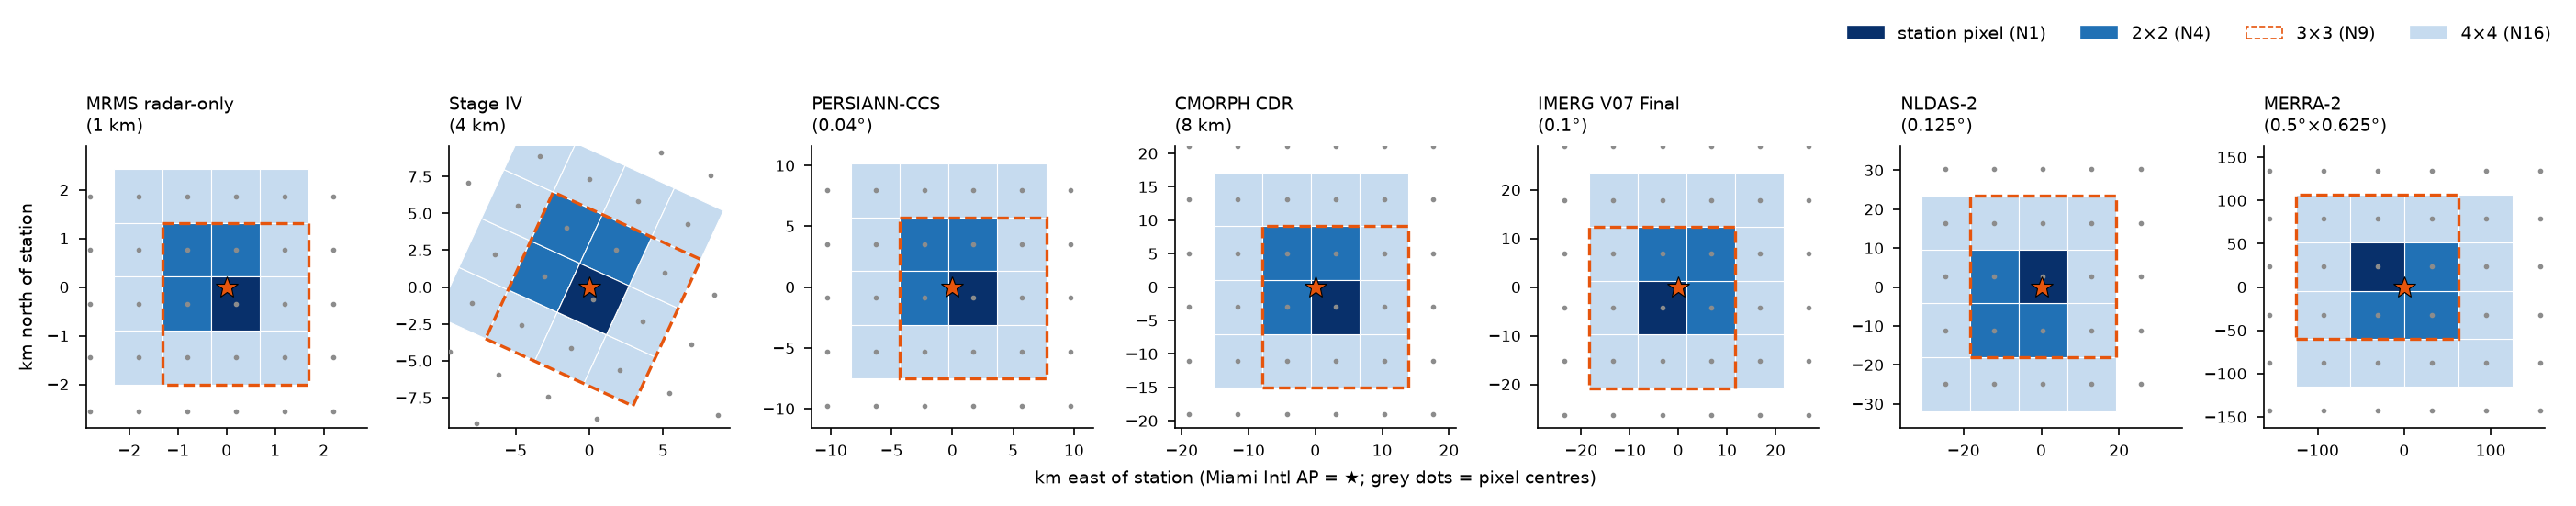

In [128]:
# [orig cell 127 | env: precip | status: ok]
from matplotlib.patches import Polygon
def corners(X,Y,a,b):
    pts=[]
    for da,db in [(-1,-1),(-1,1),(1,1),(1,-1)]:
        xs=[X[a,b],X[a+da,b],X[a,b+db],X[a+da,b+db]]; ys=[Y[a,b],Y[a+da,b],Y[a,b+db],Y[a+da,b+db]]
        pts.append((np.mean(xs),np.mean(ys)))
    return pts
fig,axs=plt.subplots(1,len(show),figsize=(14,2.7))
for ax,p in zip(axs,show):
    w=NBall[p][1]['widx'][s]; la_=np.array(w['win_lat']); lo_=np.array(w['win_lon']); m=cm.neighborhood_masks(w)
    X=(lo_-srow.lon)*111.32*np.cos(np.radians(srow.lat)); Y=(la_-srow.lat)*110.57; dxk,dyk=w['dx_km'],w['dy_km']
    for N in ['N16','N4','N1']:
        for (a,b) in zip(*np.where(m[N])): ax.add_patch(Polygon(corners(X,Y,a,b),facecolor=ncol[N],edgecolor='w',lw=0.4))
    r,c=np.where(m['N9']); cellsN9=list(zip(r,c))
    # outline N9 as union boundary: draw outer polygon via corner cells
    a0,a1,b0,b1=r.min(),r.max(),c.min(),c.max()
    poly=[corners(X,Y,a0,b0)[0],corners(X,Y,a0,b1)[1],corners(X,Y,a1,b1)[2],corners(X,Y,a1,b0)[3]]
    ax.add_patch(Polygon(poly,fill=False,edgecolor='#e6550d',lw=1.2,ls='--'))
    ax.scatter(X,Y,s=2,c='0.55',zorder=3); ax.plot(0,0,'*',c='#e6550d',ms=9,mec='k',mew=0.4,zorder=4)
    L=2.6*max(dxk,dyk); ax.set_xlim(-L,L); ax.set_ylim(-L,L); ax.set_aspect('equal')
    ax.set_title(PRODS[p].replace(' (','\n('),fontsize=7,loc='left'); ax.tick_params(labelsize=6)
axs[0].set_ylabel('km north of station',fontsize=7); axs[3].set_xlabel('km east of station (Miami Intl AP = ★; grey dots = pixel centres)',fontsize=7)
fig.legend(handles=h,loc='upper right',ncol=4,frameon=False,fontsize=7,bbox_to_anchor=(1,1.06))
fig.tight_layout(); fig.savefig('out/neighborhoods_illustration.png',dpi=200,bbox_inches='tight')

In [129]:
# [orig cell 128 | env: precip | status: ok]
recs=[]
H1mask=inH1
for p in PRODS:
    NB=NBall[p][0]
    d={'hour_start_utc':np.repeat(Hneed.values[H1mask],len(Vst)),'station':np.tile(Vst.id.values,H1mask.sum())}
    for kk,v in NB.items(): d[kk]=v[H1mask].ravel().astype(np.float32)
    df=pd.DataFrame(d); df=df[df.N1max.notna()]; df.insert(0,'product',p); recs.append(df)
NBH=pd.concat(recs); NBH['product']=NBH['product'].astype('category'); NBH['station']=NBH.station.astype('category')
NBH.to_parquet('out/product_neighborhood_hourly.parquet',compression='zstd'); print(NBH.shape, round(os.path.getsize('out/product_neighborhood_hourly.parquet')/1e6,1),'MB')
PEa.drop(columns=['key']).to_parquet('out/event_product_values.parquet',compression='zstd'); print(round(os.path.getsize('out/event_product_values.parquet')/1e6,1),'MB')
pd.Series({p:LAG.get(p,0) for p in PRODS}).rename('applied_lag_h').to_csv('out/product_time_alignment.csv')

(8397905, 11) 82.3 MB
7.9 MB


In [130]:
# [orig cell 129 | env: precip | status: ok]
apply_figure_style()
labs=[PRODS[p] for p in PRODS]; Ns=['N1','N4','N9','N16']; Nlab=['1 px','2×2','3×3','4×4']
fig,axs=plt.subplots(1,4,figsize=(12,4.2),sharey=True,gridspec_kw=dict(wspace=0.05))
for ax,T in zip(axs,[20,30,40,50]):
    M=DS[DS.threshold==T].pivot_table(index='label',columns='nbhd',values='hit_strict',sort=False).reindex(index=labs,columns=Ns)
    im=ax.imshow(M.values*100,cmap='viridis',vmin=0,vmax=80,aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v=M.values[i,j]*100; ax.text(j,i,f'{v:.0f}' if v>=1 else (f'{v:.1f}' if v>0 else '0'),ha='center',va='center',fontsize=7,color='w' if v<45 else 'k')
    n=int(DS[(DS.threshold==T)].n_events.iloc[0])
    ax.set_xticks(range(4)); ax.set_xticklabels(Nlab); ax.set_title(f'≥{T} mm/h (n={n:,} events)',loc='left')
axs[0].set_yticks(range(len(labs))); axs[0].set_yticklabels(labs)
cb=fig.colorbar(im,ax=axs,fraction=0.02,pad=0.01); cb.set_label('% of gauge events where product ≥ same threshold\n(neighborhood max, same hour)')
fig.suptitle('Radar products capture 20–77% of Florida gauge extremes; satellite and reanalysis products rarely reach the threshold',x=0.06,ha='left',y=1.0,fontsize=9)
fig.savefig('out/detection_heatmaps.png',dpi=200,bbox_inches='tight')

In [131]:
# [orig cell 130 | env: precip | status: ok]
fig._suptitle.set_text('Radar products capture 19–77% of Florida gauge extremes; satellite and reanalysis products rarely reach the threshold')
fig.savefig('out/detection_heatmaps.png',dpi=200,bbox_inches='tight')
pc={'mrms_gaugecorr':'#08306b','mrms_radaronly':'#4292c6','stage4':'#2171b5','nldas2':'#41ab5d','pccs':'#fd8d3c','cmorph':'#e6550d','imerg':'#a63603','merra2':'#737373'}
pls={'mrms_gaugecorr':'-','mrms_radaronly':'--','stage4':'-','nldas2':'-','pccs':'-','cmorph':'--','imerg':'-','merra2':'-'}
fig2,ax=plt.subplots(1,3,figsize=(12.5,3.8),gridspec_kw=dict(wspace=0.32))
for p in PRODS:
    d=DS[(DS['product']==p)&(DS.nbhd=='N1')]
    ax[0].plot(d.threshold,d.ratio_median,ls=pls[p],marker='o',ms=3,color=pc[p],label=PRODS[p])
    ax[0].fill_between(d.threshold,d.ratio_q25,d.ratio_q75,color=pc[p],alpha=0.08)
    d3=DS[(DS['product']==p)&(DS.threshold==30)].set_index('nbhd').reindex(Ns)
    ax[1].plot(range(4),d3.CSI_h,ls=pls[p],marker='o',ms=3,color=pc[p]); ax[2].plot(range(4),d3.hit_ge10,ls=pls[p],marker='o',ms=3,color=pc[p])
ax[0].axhline(1,color='0.6',lw=0.6,ls=':'); ax[0].set_xticks([20,30,40,50]); ax[0].set_xlabel('gauge threshold (mm/h)'); ax[0].set_ylabel('product ÷ gauge peak (station pixel)')
ax[0].set_title('All products underestimate peaks; worse for stronger events',loc='left'); ax[0].set_ylim(0,1.05)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(Nlab); ax[1].set_ylabel('CSI, ≥30 mm/h station-hours'); ax[1].set_title('Radar CSI peaks at 2×2; satellites keep rising',loc='left')
ax[2].set_xticks(range(4)); ax[2].set_xticklabels(Nlab); ax[2].set_ylabel('% of ≥30 mm/h events with product ≥10 mm/h'); ax[2].set_title('Relaxed detection (≥10 mm/h)',loc='left')
ax[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0))
ax[0].legend(frameon=False,fontsize=6.5,loc='upper right')
for a in ax: a.margins(x=0.05)
fig2.text(0.005,-0.02,'Shading: interquartile range. CSI/FAR universe = all station-hours within ±1 h of any gauge event (13,425 hours); common event set across products.',fontsize=6.5)
fig2.savefig('out/detection_intensity_csi.png',dpi=200,bbox_inches='tight')
print(DS[(DS.nbhd=='N1')].pivot_table(index='label',columns='threshold',values='ratio_median',sort=False).round(2))

threshold                      20    30    40    50
label                                              
MRMS gauge-corrected (1 km)  0.75  0.71  0.67  0.63
MRMS radar-only (1 km)       0.65  0.63  0.60  0.57
Stage IV (4 km)              0.64  0.62  0.60  0.59
NLDAS-2 (0.125°)             0.35  0.32  0.30  0.27
PERSIANN-CCS (0.04°)         0.10  0.10  0.10  0.10
CMORPH CDR (8 km)            0.09  0.09  0.09  0.08
IMERG V07 Final (0.1°)       0.12  0.10  0.09  0.08
MERRA-2 (0.5°×0.625°)        0.02  0.02  0.01  0.01


In [132]:
# [orig cell 131 | env: precip | status: ok]
ax[0].get_legend().remove()
for c_ in list(ax[0].collections): c_.set_alpha(0.05)
ax[0].set_title('Peaks underestimated by 25–99% at the station pixel',loc='left')
hh,ll=ax[0].get_legend_handles_labels()
fig2.legend(hh,ll,loc='lower center',ncol=4,frameon=False,fontsize=7,bbox_to_anchor=(0.5,-0.16))
fig2.texts[0].set_position((0.005,-0.2))
fig2.savefig('out/detection_intensity_csi.png',dpi=200,bbox_inches='tight')

In [133]:
# [orig cell 132 | env: precip | status: ok]
conds=['storm_type','season','time_of_day','region','coastal','urban','duration']
print([c for c in conds if c not in PEc.columns])
rows=[]
for T in [20,30,50]:
    for N in ['N1','N9']:
        d0=PEc[(PEc.threshold==T)&(PEc.nbhd==N)]
        for c in conds:
            for lev,d in d0.groupby(c):
                for p,dp in d.groupby('product'):
                    n=len(dp); h=dp.hit.mean()
                    rows.append(dict(threshold=T,nbhd=N,condition=c,level=lev,product=p,label=PRODS[p],n_events=n,n_stations=dp.STATION.nunique(),
                                     hit_strict=h,hit_se=np.sqrt(h*(1-h)/n) if n else np.nan,hit_ge10=dp.hit10.mean(),ratio_median=dp.ratio.median()))
CS=pd.DataFrame(rows); CS.to_csv('out/conditional_scores.csv',index=False)
x=CS[(CS.threshold==20)&(CS.nbhd=='N9')].pivot_table(index=['condition','level'],columns='product',values='hit_strict',sort=False)[list(PRODS)].round(2)
print(x.to_string())
print(CS[(CS.threshold==20)&(CS.nbhd=='N9')&(CS['product']=='imerg')][['condition','level','n_events']].to_string(index=False))

[]
product                                       mrms_gaugecorr  mrms_radaronly  stage4  nldas2  pccs  cmorph  imerg  merra2
condition   level                                                                                                        
storm_type  Cool-season (frontal)                       0.58            0.53    0.74    0.37  0.05    0.09   0.13    0.00
            Tropical cyclone                            0.67            0.68    0.82    0.42  0.13    0.09   0.07    0.03
            Warm-season isolated convection             0.66            0.66    0.71    0.23  0.12    0.05   0.02    0.00
            Warm-season organized (MCS-like)            0.71            0.70    0.77    0.37  0.16    0.12   0.10    0.01
season      Dry (Nov–Apr)                               0.58            0.53    0.74    0.37  0.05    0.09   0.13    0.00
            Wet (May–Oct)                               0.68            0.68    0.74    0.30  0.14    0.08   0.05    0.01
time_of_day Afternoon

In [134]:
# [orig cell 133 | env: precip | status: ok]
d=PEc[(PEc.threshold==20)&(PEc.nbhd=='N9')].copy()
d['gauge_net']=d.STATION.map(Vst.set_index('id').source_group).map({'metar':'ASOS/METAR','onhour':'Coop HPD/other'})
t=d[d['product'].isin(['stage4','mrms_gaugecorr','mrms_radaronly','nldas2','imerg','pccs'])].groupby(['product','gauge_net','urban']).agg(hit=('hit','mean'),n=('hit','size')).round(2).unstack(['gauge_net','urban'])
print(t.to_string())
print(pd.crosstab(Vst.source_group, pts.set_index('id').loc[Vst.id,'urban'].values))
# add gauge network as a condition
rows=[]
for T in [20,30,50]:
    for N in ['N1','N9']:
        dd=PEc[(PEc.threshold==T)&(PEc.nbhd==N)].copy(); dd['gauge_net']=dd.STATION.map(Vst.set_index('id').source_group).map({'metar':'ASOS/METAR','onhour':'Coop HPD/other'})
        for (lev,p),dp in dd.groupby(['gauge_net','product']):
            n=len(dp); h=dp.hit.mean()
            rows.append(dict(threshold=T,nbhd=N,condition='gauge_network',level=lev,product=p,label=PRODS[p],n_events=n,n_stations=dp.STATION.nunique(),hit_strict=h,hit_se=np.sqrt(h*(1-h)/n),hit_ge10=dp.hit10.mean(),ratio_median=dp.ratio.median()))
CS=pd.concat([CS,pd.DataFrame(rows)]); CS.to_csv('out/conditional_scores.csv',index=False)

                      hit                                     n                           
gauge_net      ASOS/METAR       Coop HPD/other       ASOS/METAR       Coop HPD/other      
urban               rural urban          rural urban      rural urban          rural urban
product                                                                                   
imerg                0.09  0.07           0.06  0.07       1805  2405           2250   490
mrms_gaugecorr       0.75  0.76           0.53  0.46       1805  2405           2250   490
mrms_radaronly       0.72  0.74           0.53  0.47       1805  2405           2250   490
nldas2               0.39  0.38           0.19  0.22       1805  2405           2250   490
pccs                 0.13  0.12           0.11  0.12       1805  2405           2250   490
stage4               0.80  0.88           0.59  0.53       1805  2405           2250   490
col_0         False  True 
source_group              
metar            24     24
onhour   

> Original cell 134 ended with status **error** in the session; it is kept for the record.

In [135]:
# [orig cell 134 | env: precip | status: error]
d=PEc[(PEc.threshold==20)&(PEc.nbhd=='N9')].copy()
d['gauge_net']=d.STATION.map(Vst.set_index('id').source_group)
print(d.groupby(['product','gauge_net'])[['hit','hit_pm1','hit10']].mean().unstack().round(2).loc[list(PRODS)].to_string())
# gauge peak intensity distribution by network
print(d[d['product']=='stage4'].groupby('gauge_net').peak_mm_h.describe()[['count','50%','90%']])

                 hit        hit_pm1        hit10       
gauge_net      metar onhour   metar onhour metar onhour
product                                                
mrms_gaugecorr  0.76   0.52    0.79   0.66  0.94   0.79
mrms_radaronly  0.73   0.52    0.77   0.68  0.95   0.79
stage4          0.84   0.58    0.89   0.73  0.96   0.83
nldas2          0.39   0.19    0.45   0.27  0.80   0.56
pccs            0.13   0.11    0.19   0.17  0.35   0.33
cmorph          0.09   0.08    0.13   0.12  0.31   0.27
imerg           0.08   0.06    0.11   0.09  0.31   0.27
merra2          0.00   0.01    0.01   0.01  0.04   0.03


Traceback (most recent call last):
  File "<kernel:76>", line 5, in <module>
    print(d[d['product']=='stage4'].groupby('gauge_net').peak_mm_h.describe()[['count','50%','90%']])
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/pandas/core/frame.py", line 4384, in __getitem__
    indexer = self.columns._get_indexer_strict(key, "columns")[1]
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/pandas/core/indexes/base.py", line 6302, in _get_indexer_strict
    self._raise_if_missing(keyarr, indexer, axis_name)
  File "~/.claude-science/conda/envs/precip/lib/python3.11/site-packages/pandas/core/indexes/base.py", line 6355, in _raise_if_missing
    raise KeyError(f"{not_found} not in index")
KeyError: "['90%'] not in index"


In [136]:
# [orig cell 135 | env: precip | status: ok]
corder=['storm_type','season','time_of_day','region','coastal','urban','duration','gauge_network']
cname={'storm_type':'Storm type','season':'Season','time_of_day':'Local time','region':'Region','coastal':'Coast','urban':'Land use','duration':'Duration','gauge_network':'Gauge network'}
lvl_order={'storm_type':['Warm-season isolated convection','Warm-season organized (MCS-like)','Tropical cyclone','Cool-season (frontal)'],'season':['Wet (May–Oct)','Dry (Nov–Apr)'],
 'time_of_day':['Night 00–06','Morning 06–12','Afternoon 12–18','Evening 18–24'],'region':['Panhandle','North','Central','South'],'coastal':['coastal (≤10 km)','inland (>10 km)'],
 'urban':['urban','rural'],'duration':['single-hour','multi-hour'],'gauge_network':['ASOS/METAR','Coop HPD/other']}
def mat(T,N,val):
    sub=CS[(CS.threshold==T)&(CS.nbhd==N)]; R=[];idx=[];nn=[]
    for c in corder:
        for l in lvl_order[c]:
            r=sub[(sub.condition==c)&(sub.level==l)].set_index('product').reindex(list(PRODS))
            R.append(r[val].values); idx.append((c,l)); nn.append(int(r.n_events.iloc[0]))
    return np.array(R),idx,nn
A1,idx,nn=mat(20,'N9','hit_strict'); A2,_,_=mat(20,'N1','ratio_median')
fig,axs=plt.subplots(1,2,figsize=(12,8.4),sharey=True,gridspec_kw=dict(wspace=0.04))
short={'mrms_gaugecorr':'MRMS\ngauge-corr','mrms_radaronly':'MRMS\nradar-only','stage4':'Stage IV','nldas2':'NLDAS-2','pccs':'PERSIANN\n-CCS','cmorph':'CMORPH','imerg':'IMERG\nFinal','merra2':'MERRA-2'}
for ax,A,ttl,vmax,fmt in [(axs[0],A1*100,'Strict hit rate, %  (≥20 mm/h events, 3×3 neighborhood)',90,'{:.0f}'),(axs[1],A2,'Median product ÷ gauge peak  (≥20 mm/h events, station pixel)',0.9,'{:.2f}')]:
    im=ax.imshow(A,cmap='viridis',vmin=0,vmax=vmax,aspect='auto')
    for i in range(A.shape[0]):
        for j in range(A.shape[1]): ax.text(j,i,fmt.format(A[i,j]),ha='center',va='center',fontsize=6.5,color='w' if A[i,j]<0.55*vmax else 'k')
    ax.set_xticks(range(8)); ax.set_xticklabels([short[p] for p in PRODS],fontsize=7); ax.xaxis.tick_top()
    ax.set_title(ttl,loc='left',pad=28,fontsize=8)
    b=0
    for c in corder[:-1]:
        b+=len(lvl_order[c]); ax.axhline(b-0.5,color='w',lw=2)
    fig.colorbar(im,ax=ax,fraction=0.035,pad=0.01,orientation='vertical')
axs[0].set_yticks(range(len(idx))); axs[0].set_yticklabels([f'{cname[c]}: {l}  (n={n:,})' for (c,l),n in zip(idx,nn)],fontsize=7)
fig.savefig('out/conditional_skill.png',dpi=200,bbox_inches='tight')

In [137]:
# [orig cell 136 | env: precip | status: ok]
fig,axs=plt.subplots(1,2,figsize=(12,8.8),sharey=True,gridspec_kw=dict(wspace=0.04))
for ax,A,ttl,vmax,fmt,cbl in [(axs[0],A1*100,'Strict hit rate (≥20 mm/h events, 3×3 neighborhood)',90,'{:.0f}','% of events with product ≥20 mm/h'),(axs[1],A2,'Peak intensity ratio (≥20 mm/h events, station pixel)',0.9,'{:.2f}','median product ÷ gauge peak')]:
    im=ax.imshow(A,cmap='viridis',vmin=0,vmax=vmax,aspect='auto')
    for i in range(A.shape[0]):
        for j in range(A.shape[1]): ax.text(j,i,fmt.format(A[i,j]),ha='center',va='center',fontsize=6.5,color='w' if A[i,j]<0.55*vmax else 'k')
    ax.set_xticks(range(8)); ax.set_xticklabels([short[p] for p in PRODS],fontsize=7); ax.xaxis.tick_top()
    ax.set_title(ttl,loc='left',pad=30,fontsize=8)
    b=0
    for c in corder[:-1]:
        b+=len(lvl_order[c]); ax.axhline(b-0.5,color='w',lw=2)
    cb=fig.colorbar(im,ax=ax,orientation='horizontal',fraction=0.025,pad=0.015,aspect=40); cb.set_label(cbl,fontsize=7)
axs[0].set_yticks(range(len(idx))); axs[0].set_yticklabels([f'{cname[c]}: {l}  (n={n:,})' for (c,l),n in zip(idx,nn)],fontsize=7)
fig.savefig('out/conditional_skill.png',dpi=200,bbox_inches='tight')
r=fig.canvas.get_renderer(); texts=[t for t in fig.findobj(mpl.text.Text) if t.get_text().strip() and t.get_visible()]
bb=[t.get_window_extent(r) for t in texts]; print(len([(i,j) for i in range(len(bb)) for j in range(i+1,len(bb)) if bb[i].overlaps(bb[j])]))

0


In [138]:
# [orig cell 137 | env: precip | status: ok]
A=lambda v:'{{!artifact:'+v+'}}'
def fmt(x,p=0): return f'{x*100:.{p}f}'
# main table
L=[]
L.append('| Product | Type | ≥20: 1 px | ≥20: 4×4 | ≥30: 1 px | ≥30: 4×4 | ≥50: 1 px | ≥50: 4×4 | peak ratio (≥30, 1 px) | best CSI (≥30) |')
L.append('|---|---|---|---|---|---|---|---|---|---|')
for p in PRODS:
    r=lambda T,N: DS[(DS['product']==p)&(DS.threshold==T)&(DS.nbhd==N)].iloc[0]
    cs=DS[(DS['product']==p)&(DS.threshold==30)].set_index('nbhd').CSI_h
    cells=[]
    for T in [20,30,50]:
        for N in ['N1','N16']:
            x=r(T,N); cells.append(f"{fmt(x.hit_strict,0 if x.hit_strict>=0.1 else 1)}% ({fmt(x.hit_strict_lo,0 if x.hit_strict>=0.1 else 1)}–{fmt(x.hit_strict_hi,0 if x.hit_strict>=0.1 else 1)})")
    L.append(f"| {PRODS[p]} | {PTYPE[p]} | "+' | '.join(cells)+f" | {r(30,'N1').ratio_median:.2f} | {cs.max():.2f} ({dict(zip(Ns,Nlab))[cs.idxmax()]}) |")
main_table='\n'.join(L)
nev={T:int(DS[DS.threshold==T].n_events.iloc[0]) for T in EV}
g=lambda c,l,p,T=20,N='N9',v='hit_strict': CS[(CS.condition==c)&(CS.level==l)&(CS['product']==p)&(CS.threshold==T)&(CS.nbhd==N)][v].iloc[0]
summ=pd.read_csv('out/event_counts_summary.csv').set_index('threshold')
print(main_table); print(nev)

| Product | Type | ≥20: 1 px | ≥20: 4×4 | ≥30: 1 px | ≥30: 4×4 | ≥50: 1 px | ≥50: 4×4 | peak ratio (≥30, 1 px) | best CSI (≥30) |
|---|---|---|---|---|---|---|---|---|---|
| MRMS gauge-corrected (1 km) | radar+gauge | 53% (48–57) | 69% (65–73) | 43% (38–48) | 58% (54–63) | 33% (27–39) | 44% (38–50) | 0.71 | 0.35 (2×2) |
| MRMS radar-only (1 km) | radar | 46% (42–50) | 70% (66–73) | 36% (33–40) | 58% (54–62) | 19% (14–23) | 36% (32–40) | 0.63 | 0.28 (2×2) |
| Stage IV (4 km) | radar+gauge | 44% (40–49) | 77% (72–81) | 35% (31–39) | 70% (65–75) | 24% (19–30) | 61% (53–67) | 0.62 | 0.32 (2×2) |
| NLDAS-2 (0.125°) | gauge/radar-based reanalysis forcing | 17% (15–20) | 33% (30–36) | 8.7% (6.8–10.9) | 20% (17–23) | 2.7% (1.3–4.7) | 6.7% (4.3–9.5) | 0.32 | 0.14 (3×3) |
| PERSIANN-CCS (0.04°) | satellite (IR) | 5.0% (4.3–5.5) | 15% (14–16) | 2.6% (2.1–3.2) | 8.1% (6.9–9.4) | 0.4% (0.0–1.1) | 1.8% (0.7–3.1) | 0.10 | 0.04 (4×4) |
| CMORPH CDR (8 km) | satellite (MW+IR, bias-corrected) | 3.3% (2.

In [139]:
# [orig cell 138 | env: precip | status: ok]
st=lambda p,l: round(g('storm_type',l,p)*100)
stt=['Warm-season isolated convection','Warm-season organized (MCS-like)','Tropical cyclone','Cool-season (frontal)']
sat_rows='\n'.join(f"| {PRODS[p]} | "+' | '.join(f"{st(p,l)}% / {g('storm_type',l,p,N='N1',v='ratio_median'):.2f}" for l in stt)+' |' for p in ['stage4','mrms_radaronly','pccs','cmorph','imerg'])
nst={l:int(CS[(CS.condition=='storm_type')&(CS.level==l)&(CS.threshold==20)&(CS.nbhd=='N9')].n_events.iloc[0]) for l in stt}
rep=f"""# How well do gridded precipitation products capture hourly rainfall extremes in Florida? (2015–2025)

**Ground truth:** GHCNh hourly gauges. **Products:** 8 gridded datasets. **Thresholds:** ≥20, ≥30, ≥40, ≥50 mm/h. **Neighborhoods:** 1, 2×2, 3×3, 4×4 pixels.

## 1. Ground truth (GHCNh)
* Of the 256 Florida GHCNh stations, 132 report hourly precipitation. **79 pass the validity rule:** at least 5 years in 2015–2025, each with at least 30 complete UTC days (24 valid hourly values). 48 are ASOS/METAR stations and 31 are Coop HPD or other hourly gauges ([valid_stations.csv]({A('bfe55394-da4a-4de1-88d3-c2d1b0631358')})).
* **How the hourly values were built.** METAR hourly totals use the last routine FM‑15 report of the clock hour (minute ≥45). That report holds the running total for the hour, as the GHCNh documentation (section IX) specifies. Each value is assigned to the hour starting at HH:00 UTC. Records with quality code 2 (suspect) or G (failed gap check) were removed.
* **Why stations fail.** Military airfields and many AWOS sites only carry a precipitation value when rain occurs. They therefore can never show 24 complete hours and fail the rule. They could be recovered if a missing precipitation group in a routine report were treated as zero.
* **Event lists.** An event is one or more exceedance hours at a station, with hours less than 6 h apart merged into one event. Isolated spikes and values above 150 mm/h are *flagged* in the lists and excluded from scoring.

| threshold | exceedance hours | events | stations |
|---|---|---|---|
""" + '\n'.join(f"| ≥{T} mm/h | {summ.loc[T,'hours']:,} | {summ.loc[T,'events']:,} | {summ.loc[T,'stations']} |" for T in [20,30,40,50]) + f"""

Event lists: [≥20]({A('4241cce7-e586-470b-8e92-dc60d1bf59f5')}), [≥30]({A('2dc5f190-c184-4856-ad87-2e045e782e2e')}), [≥40]({A('c9aa3fcc-1ac0-4bca-99d0-b2428c74f0f2')}), [≥50]({A('d05bde1e-c0e9-4cd3-b2f5-69ba46b3ac9f')}). Each row carries its condition labels.

![Station screening]({A('fe6f5182-27c3-4a50-976c-b43e507cef56')})
![Event climatology]({A('777d5794-42f4-484f-aa6e-20bbed4edeb9')})

## 2. Products and method
| Product | Resolution | Source / access |
|---|---|---|
| MRMS gauge-corrected | 1 km, hourly | GaugeCorr_QPE_01H until Oct 2020, then MultiSensor_QPE_01H_Pass2 (Iowa State mtarchive) |
| MRMS radar-only | 1 km, hourly | RadarOnly_QPE_01H (Iowa State mtarchive) |
| Stage IV | 4 km, hourly | NCEP ST4 01h (Iowa State mesonet archive) |
| NLDAS-2 forcing | 0.125°, hourly | NASA Cloud OPeNDAP (domain starts at 25.06°N, so the Keys are not covered) |
| PERSIANN-CCS | 0.04°, hourly | UC Irvine CHRS |
| CMORPH v1 CDR | 8 km, 30 min | NOAA NCEI |
| IMERG V07 Final | 0.1°, 30 min | NASA Cloud OPeNDAP (available through 29 Sep 2025) |
| MERRA-2 PRECTOTCORR | 0.5°×0.625°, hourly | NASA Cloud OPeNDAP |

**Not evaluated.** ERA5 and ERA5-Land need a Copernicus CDS personal access token; the stored credential is an account password, which the API rejects. GSMaP needs a JAXA account.

**Timing check.** Each product's time convention was verified against the gauges by lag correlation over all station-hours. IMERG, CMORPH, PERSIANN-CCS, Stage IV and both MRMS versions peak at lag 0. NLDAS-2 peaks at +1 h, meaning its timestamps mark the end of the hour, so it was shifted by 1 h. MERRA-2 has a flat lag profile ([product_time_alignment.csv]({A('c190aa76-d767-4d0f-98d7-7e0fd9e38131')})).

**Neighborhoods.**
* N1 is the pixel containing the station.
* N4 and N16 are the 2×2 and 4×4 blocks whose centre is closest to the station.
* N9 is the 3×3 block centred on N1.
* Each neighborhood's value is its pixel **maximum**. Physical size differs enormously: N16 is 17 km² for MRMS but 54,585 km² for MERRA-2 ([neighborhood_definitions.csv]({A('93d15251-fefc-443c-b1e8-00537cf9cf7a')})).

![Neighborhood definitions]({A('94ffc7d7-916c-45d8-9dc8-bf81448fabde')})

**Metrics.** All metrics use the **common event set**: events where every product has data, giving {nev[20]:,} / {nev[30]:,} / {nev[40]:,} / {nev[50]:,} events for ≥20/30/40/50 mm/h.
* *Strict hit:* the product's neighborhood maximum in the same hour reaches the same threshold. Confidence intervals are 95% station-block bootstrap.
* *Relaxed hit:* the product reaches ≥10 mm/h.
* *Peak ratio:* product ÷ gauge peak.
* *POD/FAR/CSI:* computed over all station-hours within ±1 h of any gauge event (13,425 hours). This window concentrates on storm hours, so FAR here is not a climatological false-alarm rate.

## 3. Results — which product catches the extremes?
{main_table}

Hit-rate cells give strict hit rate (95% CI); "4×4" is the 16-pixel neighborhood. Full tables: [detection_scores.csv]({A('3a3f198f-ddb6-4d2a-ad54-213e00f2a0df')}).

![Detection heatmaps]({A('8064c32d-4e18-46df-bb13-7c228ee3f015')})
![Intensity ratio and CSI]({A('5b7c6273-2220-4626-8ca5-89105b4cf12b')})

**Key findings**
1. **Radar products are the only ones that routinely reach the gauge threshold.** At the station pixel, MRMS gauge-corrected is best (53% of ≥20 mm/h and 33% of ≥50 mm/h events). With larger neighborhoods, Stage IV overtakes it: 77% (≥20) and 61% (≥50) at 4×4, a 16 km box. Radar-only MRMS stays close to the gauge-corrected version for moderate thresholds but falls behind for ≥50 mm/h (19% vs 33% at 1 px).
2. **Neighborhood size has opposite effects for radar and satellite products.** For radar, hit rates rise with neighborhood size, but CSI peaks at 2×2 and then falls because false alarms grow. For satellites, CSI keeps rising up to 4×4: their errors are dominated by smoothing and displacement, not false alarms.
3. **Satellite products miss the intensity, not the storm.** IMERG, CMORPH and PERSIANN-CCS detect rain ≥10 mm/h at a 4×4 neighborhood in about 40–48% of ≥30 mm/h events. They almost never reach the gauge value: median peak ratio is about 0.10, and the strict hit rate is ≤3% at ≥30 mm/h even at 4×4. PERSIANN-CCS, at 0.04° and IR-based, has the highest strict hit rate of the satellites.
4. **The reanalyses are unsuitable for hourly extremes.** MERRA-2 essentially never reaches 20 mm/h (peak ratio 0.01–0.02). NLDAS-2 does better (17–33% at ≥20 mm/h) only because its hourly precipitation is built from gauges and Stage II/IV radar.
5. **Every product underestimates peaks, and radar does so more for stronger events.** MRMS gauge-corrected falls from a ratio of 0.75 at ≥20 mm/h to 0.63 at ≥50 mm/h.

## 4. In which conditions? ({nst[stt[0]]:,} isolated convection, {nst[stt[1]]:,} organized/MCS-like, {nst[stt[2]]:,} tropical cyclone, {nst[stt[3]]:,} cool-season events at ≥20 mm/h)
Each cell gives the strict hit rate at 3×3 / median peak ratio at the station pixel.

| Product | Warm-season isolated convection | Warm-season organized (MCS-like) | Tropical cyclone | Cool-season (frontal) |
|---|---|---|---|---|
{sat_rows}

![Conditional skill]({A('0f5edb15-8d13-47c6-a6d3-882796a4fca7')})

* **Storm type.**
  * *Isolated warm-season convection is the hardest case for every product.* IMERG catches 2% (3×3) with a median ratio of 0.06.
  * *Microwave-based products (IMERG, CMORPH) do relatively best on cool-season frontal and organized or tropical-cyclone systems.* IMERG reaches 13% and a ratio of 0.20 in the cool season.
  * *IR-only PERSIANN-CCS behaves the opposite way.* It is best in warm-season organized convection (16%) and worst in the cool season (5%), consistent with its cold-cloud-top retrieval.
  * *Stage IV is strongest for tropical cyclones* (82%).
* **Season and time of day.** Radar skill hardly changes with time of day. Satellite skill differs mainly through storm type: IMERG does better at night and in the morning, PERSIANN-CCS in the afternoon and evening.
* **Duration.** Multi-hour events are captured much better than single-hour bursts by every product; Stage IV reaches 86% vs 72%.
* **Coastal and urban.** Stage IV scores higher at coastal (80% vs 69%) and urban (82% vs 68%) stations. This is **largely a gauge-network effect.** Within ASOS stations only, urban and rural differ little (Stage IV 0.88 vs 0.80; MRMS gauge-corrected 0.76 vs 0.75).
* **Gauge network matters more than any meteorological condition.** All radar products score about 20 percentage points lower at Coop HPD gauges than at ASOS gauges, and this holds even for gauge-free MRMS radar-only (0.52 vs 0.73). Allowing ±1 h timing closes about half the gap: for Stage IV, Coop rises from 0.58 to 0.73 while ASOS goes from 0.84 to 0.89. So part of the gap is timestamp or representativeness uncertainty in the Coop hourly series. *For scaling studies, ASOS hourly totals are the cleaner reference.*

Full condition tables, including ≥30 and ≥50 mm/h and N1/N9: [conditional_scores.csv]({A('a42733a6-f396-42e9-bc04-342198ebe4d1')}).

## 5. Caveats
* **The ground truth is not fully independent of some products.** MRMS gauge-corrected, Stage IV and NLDAS-2 assimilate gauge data, including hourly ASOS/HADS gauges that may be the very stations used here. MRMS radar-only is the cleanest radar benchmark.
* **Points and areas differ in scale.** A gauge measures a point, while a product cell averages up to 3,400 km² (MERRA-2). Coarse products *cannot* reach point extremes even when they are perfect area averages, so the strict hit rate measures usefulness for point-extreme work, not retrieval error alone.
* **The storm-type labels are proxies.**
  * TC = IBTrACS centre within 500 km.
  * Cool-season = Nov–Apr and not a TC.
  * Warm-season organized vs isolated is decided by the IMERG ≥2 mm/h rain-object area at the peak hour (≥10,000 km² = organized). IMERG misses are classed as isolated, which slightly penalises IMERG within that class.
  * A tracked MCS database (e.g., the PyFLEXTRKR MCS dataset of Feng and colleagues) would give a stronger separation of mesoscale convective systems.
* **Coverage.** The Keys stations drop out of the common set because NLDAS-2 does not cover them. IMERG Final ends on 29 Sep 2025. MRMS gauge-corrected is missing some early-2015 hours.
* **Land-use proxy.** Urban/rural comes from Natural Earth urban polygons, a coarse proxy; NLCD impervious fraction would be better.

## 6. Data/checkpoint files
* [event_product_values.parquet]({A('f04a41e3-4c43-46c8-8c46-0bc329540e5d')}): per event × product × neighborhood values.
* [product_neighborhood_hourly.parquet]({A('81b24e90-efa5-41c6-900e-845d133b5740')}): neighborhood max/mean for every station × hour × product.
* [station_attributes.csv]({A('48b57b5b-1fd9-4a98-a472-0649ffe3ed81')}): station region, distance to coast and urban flag.
"""
open('out/report.md','w').write(rep); print(len(rep)); print(sat_rows)

12407
| Stage IV (4 km) | 71% / 0.56 | 77% / 0.68 | 82% / 0.73 | 74% / 0.70 |
| MRMS radar-only (1 km) | 66% / 0.63 | 70% / 0.69 | 68% / 0.73 | 53% / 0.59 |
| PERSIANN-CCS (0.04°) | 12% / 0.04 | 16% / 0.18 | 13% / 0.11 | 5% / 0.07 |
| CMORPH CDR (8 km) | 5% / 0.03 | 12% / 0.16 | 9% / 0.15 | 9% / 0.17 |
| IMERG V07 Final (0.1°) | 2% / 0.06 | 10% / 0.18 | 7% / 0.18 | 13% / 0.20 |


In [140]:
# [orig cell 139 | env: precip | status: ok]
rep=rep.replace("and the strict hit rate is ≤3% at ≥30 mm/h even at 4×4","and even at 4×4 the strict hit rate at ≥30 mm/h is only 3–8%")
rep=rep.replace("Radar skill hardly changes with time of day.","Stage IV is flat across the day (73–75%), while MRMS is about 10 points lower at night and in the morning (gauge-corrected 60–62% vs 67–68%).")
rep=rep.replace("All radar products score about 20 percentage points lower","All radar products score 21–26 percentage points lower")
assert "3–8%" in rep and "73–75%" in rep and "21–26" in rep
open('out/report.md','w').write(rep)